<a href="https://colab.research.google.com/github/Simranpurswani/data-science-machine-learning-assignments/blob/main/booking%20cancellation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os, re, sys, hashlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

SEED = 42                      # fixed so every student gets the same numbers
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 40)
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", __import__("sklearn").__version__)

pandas 2.2.3 | numpy 2.1.3 | scikit-learn 1.6.1


In [ ]:
bookings = pd.read_csv("hotel_bookings.csv")          # upload hotel_bookings.csv to Colab first
print("rows, columns:", bookings.shape)
bookings[["hotel", "lead_time", "arrival_date_month", "stays_in_week_nights", "adults",
          "market_segment", "deposit_type", "customer_type", "adr"]].head(5)

rows, columns: (119390, 32)


,hotel,lead_time,arrival_date_month,stays_in_week_nights,adults,market_segment,deposit_type,customer_type,adr
0,Resort Hotel,342,July,0,2,Direct,No Deposit,Transient,0.0
1,Resort Hotel,737,July,0,2,Direct,No Deposit,Transient,0.0
2,Resort Hotel,7,July,1,1,Direct,No Deposit,Transient,75.0
3,Resort Hotel,13,July,1,1,Corporate,No Deposit,Transient,75.0
4,Resort Hotel,14,July,2,2,Online TA,No Deposit,Transient,98.0


In [ ]:
AI_ROWS = [7964, 11842, 26469, 34058, 42768, 43295, 63373, 65473, 67541, 72416,
           72977, 77903, 78307, 78400, 93460, 102118, 105293, 107225, 109161, 110616]
view = bookings.loc[AI_ROWS, ["hotel", "lead_time", "arrival_date_month", "stays_in_weekend_nights",
                              "stays_in_week_nights", "adults", "market_segment", "deposit_type",
                              "customer_type", "previous_cancellations", "is_repeated_guest", "adr"]].copy()
view["nights"] = view.stays_in_weekend_nights + view.stays_in_week_nights
view["arrives"] = view.arrival_date_month.str[:3]
view = view.drop(columns=["stays_in_weekend_nights", "stays_in_week_nights", "arrival_date_month"])
view.insert(0, "booking_id", range(1, 21))
view.set_index("booking_id")

,hotel,lead_time,adults,market_segment,deposit_type,customer_type,previous_cancellations,is_repeated_guest,adr,nights,arrives
booking_id,,,,,,,,,,,
1,Resort Hotel,116,2,Online TA,No Deposit,Transient,0,0,199.00,1,Sep
2,Resort Hotel,104,2,Direct,No Deposit,Transient,0,0,121.50,5,Jun
3,Resort Hotel,26,2,Online TA,No Deposit,Transient,0,0,192.00,2,Jul
4,Resort Hotel,171,2,Groups,No Deposit,Transient-Party,0,0,71.00,7,Mar
5,City Hotel,87,2,Corporate,No Deposit,Transient-Party,0,0,100.00,1,Sep
6,City Hotel,16,1,Direct,No Deposit,Group,0,0,132.67,3,Sep
7,City Hotel,45,2,Online TA,No Deposit,Transient,0,0,95.40,2,Feb
8,City Hotel,112,2,Offline TA/TO,Non Refund,Transient,0,0,95.00,2,Apr
9,City Hotel,28,2,Online TA,No Deposit,Transient,0,0,169.00,3,May


In [ ]:
# Recorded in advance from an AI chat that saw only the table above. Same for every class.
AI_PICKS = [7964, 72977, 72416]          # row labels of the 3 bookings it chose
print("AI chose booking ids:", [AI_ROWS.index(i) + 1 for i in AI_PICKS])

AI chose booking ids: [1, 11, 10]


In [ ]:
LATE_CANCELLED = [42768, 77903]

In [ ]:
check = pd.DataFrame({"booking_id": range(1, 21)}, index=AI_ROWS)
check["cancelled_late"] = [1 if i in LATE_CANCELLED else 0 for i in AI_ROWS]
check["AI flagged"] = [1 if i in AI_PICKS else 0 for i in AI_ROWS]
check.set_index("booking_id").T

booking_id,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
cancelled_late,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
AI flagged,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0


In [ ]:
tp = int(((check["AI flagged"] == 1) & (check["cancelled_late"] == 1)).sum())
fp = int(((check["AI flagged"] == 1) & (check["cancelled_late"] == 0)).sum())
fn = int(((check["AI flagged"] == 0) & (check["cancelled_late"] == 1)).sum())
tn = int(((check["AI flagged"] == 0) & (check["cancelled_late"] == 0)).sum())
print("TP", tp, "| FP", fp, "| FN", fn, "| TN", tn)

accuracy = (tp + tn) / 20
print(f"\nAccuracy of the AI's picks: {accuracy:.0%}")
print(f"Accuracy of 'nobody will cancel': {(20 - 2) / 20:.0%}")

TP 0 | FP 3 | FN 2 | TN 15

Accuracy of the AI's picks: 75%
Accuracy of 'nobody will cancel': 90%


In [ ]:
precision = tp / (tp + fp) if (tp + fp) else 0
recall = tp / (tp + fn) if (tp + fn) else 0
print(f"Precision: {precision:.0%}   Recall: {recall:.0%}")

Precision: 0%   Recall: 0%


In [ ]:
print("rows, columns:", bookings.shape)
print("share cancelled at any time:", round(bookings.is_canceled.mean(), 3))
print("exact duplicate rows:", bookings.duplicated().sum())
print("\nmissing values (columns that have any):")
print(bookings.isna().sum()[lambda s: s > 0])
print("\nreservation_status counts:")
print(bookings.reservation_status.value_counts())

rows, columns: (119390, 32)
share cancelled at any time: 0.37
exact duplicate rows: 31994

missing values (columns that have any):
children         4
country        488
agent        16340
company     112593
dtype: int64

reservation_status counts:
reservation_status
Check-Out    75166
Canceled     43017
No-Show       1207
Name: count, dtype: int64


In [ ]:
n_raw = len(bookings)
data = bookings.drop_duplicates().copy()            # keeps the original row labels
print("rows:", n_raw, "->", len(data))

rows: 119390 -> 87396


In [ ]:
MONTHS = {m: i for i, m in enumerate(["January", "February", "March", "April", "May", "June", "July",
                                      "August", "September", "October", "November", "December"], 1)}
arrival = pd.to_datetime(dict(year=data.arrival_date_year,
                              month=data.arrival_date_month.map(MONTHS),
                              day=data.arrival_date_day_of_month))
days_before = (arrival - pd.to_datetime(data.reservation_status_date)).dt.days

data["last_minute_cancel"] = ((data.is_canceled == 1) & (days_before <= 14)).astype(int)
data["arrival_month"] = data.arrival_date_month.map(MONTHS)

print("bookings:", len(data))
print("last-minute cancels:", int(data.last_minute_cancel.sum()))
print(f"share: {data.last_minute_cancel.mean():.2%}")
print("\nsanity check, our 20 bookings:", sorted(data.loc[AI_ROWS][data.loc[AI_ROWS].last_minute_cancel == 1].index.tolist()), "(should be", sorted(LATE_CANCELLED), ")")

bookings: 87396
last-minute cancels: 7301
share: 8.35%

sanity check, our 20 bookings: [42768, 77903] (should be [42768, 77903] )


In [ ]:
data["children"] = data["children"].fillna(0)
print("missing children values left:", int(data["children"].isna().sum()))

missing children values left: 0


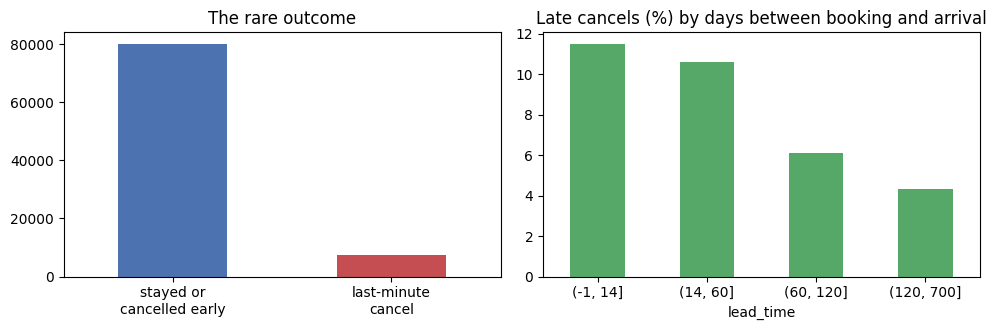

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
data.last_minute_cancel.value_counts().sort_index().plot.bar(ax=ax[0], color=["#4C72B0", "#C44E52"], rot=0)
ax[0].set_xticklabels(["stayed or\ncancelled early", "last-minute\ncancel"]); ax[0].set_title("The rare outcome"); ax[0].set_xlabel("")
data.groupby(pd.cut(data.lead_time, [-1, 14, 60, 120, 700]), observed=False).last_minute_cancel.mean().mul(100).plot.bar(ax=ax[1], color="#55A868", rot=0)
ax[1].set_title("Late cancels (%) by days between booking and arrival"); ax[1].set_xlabel("lead_time")
plt.tight_layout(); plt.show()

In [ ]:
NUMERIC = ["lead_time", "adults", "children", "babies", "stays_in_weekend_nights", "stays_in_week_nights",
           "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled",
           "days_in_waiting_list", "adr", "arrival_month"]
CATEGORICAL = ["hotel", "meal", "market_segment", "distribution_channel", "reserved_room_type",
               "deposit_type", "customer_type"]

NOT_USED = ["is_canceled", "reservation_status", "reservation_status_date", "assigned_room_type",
            "booking_changes", "required_car_parking_spaces", "total_of_special_requests"]
print("Columns we deliberately leave out for now:", NOT_USED)

Columns we deliberately leave out for now: ['is_canceled', 'reservation_status', 'reservation_status_date', 'assigned_room_type', 'booking_changes', 'required_car_parking_spaces', 'total_of_special_requests']


In [ ]:
y = data["last_minute_cancel"]
train_idx, test_idx = train_test_split(data.index, test_size=0.3, random_state=SEED, stratify=y)
y_train, y_test = y.loc[train_idx], y.loc[test_idx]
print("train bookings:", len(train_idx), "| test bookings:", len(test_idx))
print(f"late-cancel share  train {y_train.mean():.2%}  test {y_test.mean():.2%}")
assert all(i in test_idx for i in AI_ROWS), "our 20 bookings must be in the hidden test set"

train bookings: 61177 | test bookings: 26219
late-cancel share  train 8.35%  test 8.35%
